In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df_house = pd.read_csv("cleandataset.csv")
df_house.head()

,id,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view_quality,condition,grade,...,lat,long,sqft_living15,sqft_lot15,date,price,basement_was_missing,view_was_missing,is_renovated,renovated_was_missing
0,7129300520,3.0,1.00,1180.0,5650.0,1.0,0,0.0,3,7,...,47.5112,-122.257,1340.0,5650.0,2014-10-13,221900.0,0,0,0,0
1,6414100192,3.0,2.25,2570.0,7242.0,2.0,0,0.0,3,7,...,47.7210,-122.319,1690.0,7639.0,2014-12-09,538000.0,0,0,1,0
2,5631500400,2.0,1.00,770.0,10000.0,1.0,0,0.0,3,6,...,47.7379,-122.233,2720.0,8062.0,2015-02-25,180000.0,0,0,0,0
3,2487200875,4.0,3.00,1960.0,5000.0,1.0,0,0.0,5,7,...,47.5208,-122.393,1360.0,5000.0,2014-12-09,604000.0,0,0,0,0
4,1954400510,3.0,2.00,1680.0,8080.0,1.0,0,0.0,3,8,...,47.6168,-122.045,1800.0,7503.0,2015-02-18,510000.0,0,0,0,0


In [9]:
from matplotlib import font_manager

available = sorted({f.name for f in font_manager.fontManager.ttflist})
print(available)
print("Verdana" in available)

['.ADT Slab Numeric', '.ADT Slab Soft Numeric', '.Al Bayan PUA', '.Al Nile PUA', '.Al Tarikh PUA', '.Apple SD Gothic NeoI', '.Aqua Kana', '.Aqua Kana Bold', '.Arial Hebrew Desk Interface', '.Baghdad PUA', '.Beirut PUA', '.CJK Symbols Fallback HK', '.CJK Symbols Fallback JA', '.CJK Symbols Fallback MO', '.CJK Symbols Fallback SC', '.CJK Symbols Fallback TC', '.CJK Symbols Fallback Watch HK', '.CJK Symbols Fallback Watch JA', '.CJK Symbols Fallback Watch MO', '.CJK Symbols Fallback Watch SC', '.CJK Symbols Fallback Watch TC', '.Damascus PUA', '.DecoType Naskh PUA', '.DecoType Nastaleeq Urdu UI', '.Diwan Kufi PUA', '.Farah PUA', '.Geeza Pro Interface', '.Geeza Pro PUA', '.Hiragino Kaku Gothic Interface', '.Hiragino Sans GB Interface', '.Keyboard', '.KufiStandardGK PUA', '.Lucida Grande UI', '.Muna PUA', '.Nadeem PUA', '.New York', '.New York Numeric', '.New York Soft Numeric', '.Noto Nastaliq Urdu UI', '.SF Adaptive Numeric', '.SF Adaptive Soft Numeric', '.SF Arabic', '.SF Arabic Rounded'

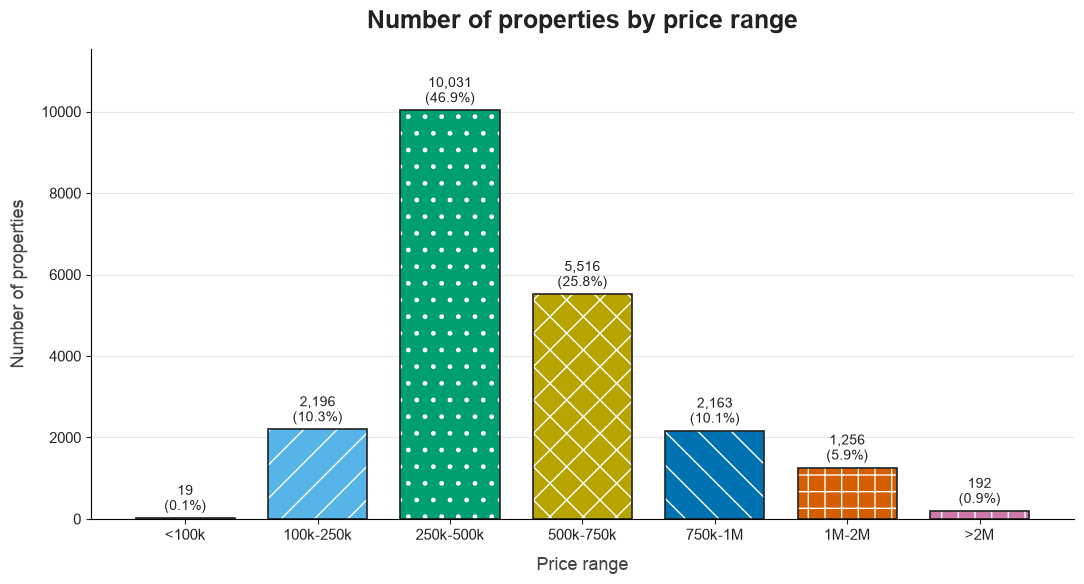

In [16]:
import matplotlib.pyplot as plt
import pandas as pd
plt.rcParams["font.family"] = "Arial"

# Price segments
bins = [0, 100_000, 250_000, 500_000, 750_000, 1_000_000, 2_000_000, float("inf")]
labels = ["<100k", "100k-250k", "250k-500k", "500k-750k", "750k-1M", "1M-2M", ">2M"]
df_unique = df_house.sort_values("date").drop_duplicates(subset="id", keep="last").copy()
df_unique["price_range"] = pd.cut(df_unique["price"], bins=bins, labels=labels, right=False)

counts = df_unique["price_range"].value_counts().reindex(labels)
share = counts / counts.sum() * 100

# Okabe-Ito colorblind-safe palette; darker tones so white texture stays visible
colors = ["#E69F00", "#56B4E9", "#009E73", "#B8A400", "#0072B2", "#D55E00", "#CC79A7"]
# sparse patterns (single characters = wide spacing, much less busy)
hatches = ["", "/", ".", "x", "\\", "+", "|"]

plt.rcParams["hatch.linewidth"] = 1.0  
     # thin hatch lines

fig, ax = plt.subplots(figsize=(11, 6))

# layer 1: colored bars with WHITE hatch (hatch color = edgecolor)
bars = ax.bar(labels, counts, color=colors, edgecolor="white", linewidth=0, width=0.75)
for bar, h in zip(bars, hatches):
    bar.set_hatch(h)
    bar.set_edgecolor("white")

# layer 2: thin dark outline on top, so every bar stays clearly defined
ax.bar(labels, counts, fill=False, edgecolor="#222222", linewidth=1.2, width=0.75)

# value labels on top of each bar
for bar, n, pct in zip(bars, counts, share):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + counts.max() * 0.01,
            f"{n:,}\n({pct:.1f}%)", ha="center", va="bottom", fontsize=10)

ax.set_title("Number of properties by price range",
             fontsize=18, fontweight="bold", color="#222222", pad=15)
ax.set_xlabel("Price range",
              fontsize=13, color="#444444", labelpad=10)
ax.set_ylabel("Number of properties",
              fontsize=13, color="#444444", labelpad=10)
ax.set_ylim(0, counts.max() * 1.15)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)

plt.tight_layout()
plt.show()

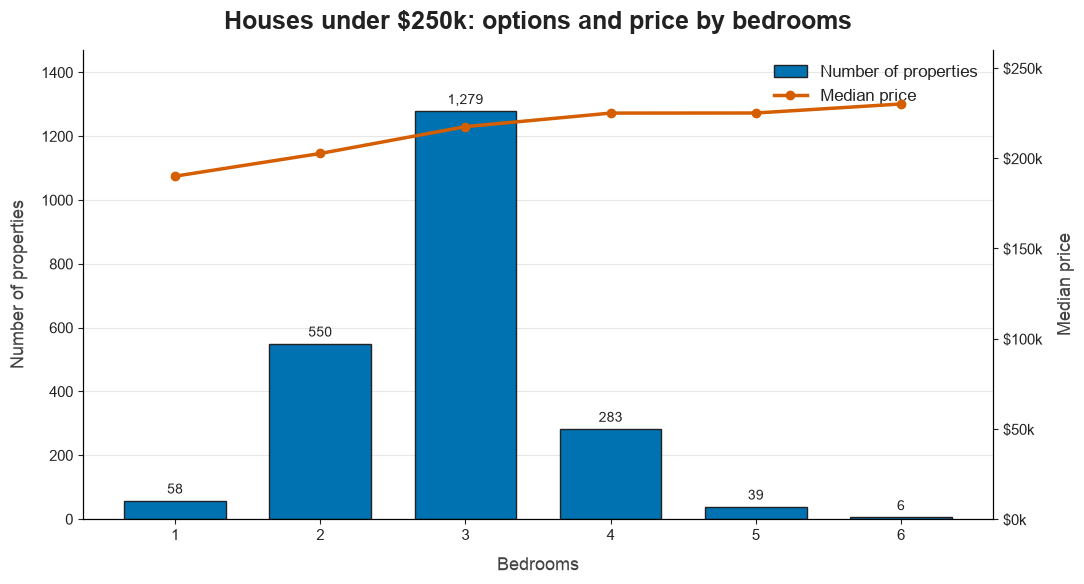

In [17]:
from matplotlib.ticker import FuncFormatter

budget = df_unique[df_unique["price"] < 250_000].copy()

by_bed = budget.groupby("bedrooms").agg(n=("price", "size"),
                                        median_price=("price", "median"))
x = by_bed.index.astype(int).astype(str)

fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.bar(x, by_bed["n"], color="#0072B2", edgecolor="#222222",
              width=0.7, label="Number of properties")
for bar, n in zip(bars, by_bed["n"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + by_bed["n"].max() * 0.01,
            f"{n:,}", ha="center", va="bottom", fontsize=10)

ax2 = ax.twinx()
ax2.plot(x, by_bed["median_price"], color="#D55E00", marker="o",
         linewidth=2.5, label="Median price")
ax2.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v/1000:.0f}k"))
ax2.set_ylim(0, 260_000)
ax2.set_ylabel("Median price", fontsize=13, color="#444444", labelpad=10)

ax.set_title("Houses under $250k: options and price by bedrooms",
             fontsize=18, fontweight="bold", color="#222222", pad=15)
ax.set_xlabel("Bedrooms", fontsize=13, color="#444444", labelpad=10)
ax.set_ylabel("Number of properties", fontsize=13, color="#444444", labelpad=10)
ax.set_ylim(0, by_bed["n"].max() * 1.15)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax2.spines["top"].set_visible(False)

h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper right", frameon=False)

plt.tight_layout()
plt.show()

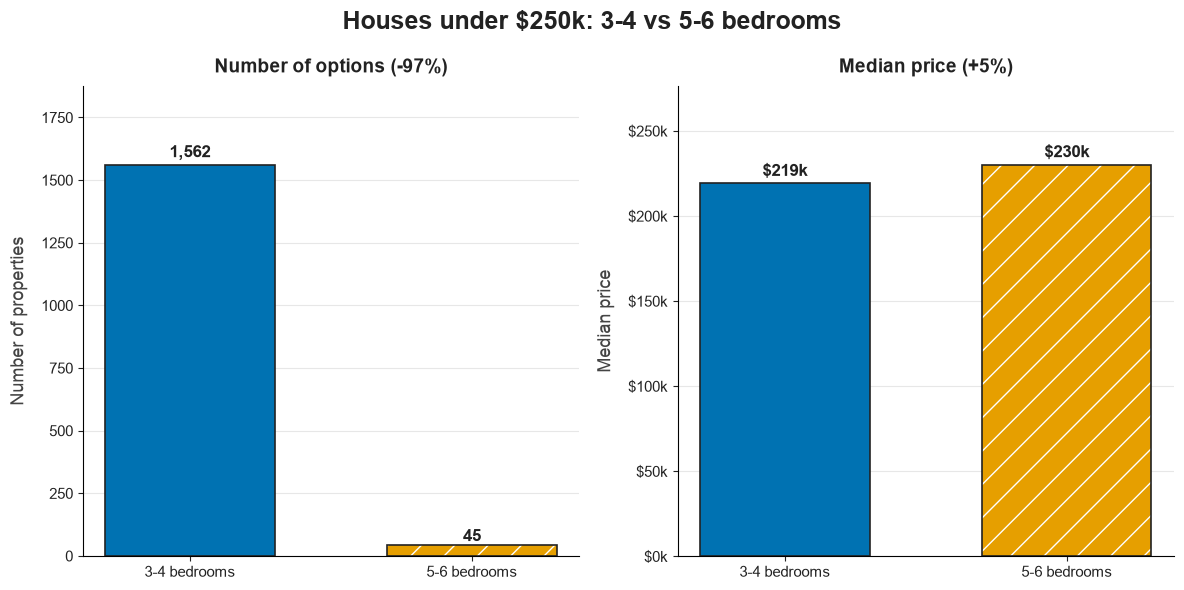

bed_group
3-4 bedrooms    455000.0
5-6 bedrooms    624500.0
Name: price, dtype: float64
Full market: 5-6 vs 3-4 bedrooms = +37%


In [23]:
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import FuncFormatter
plt.rcParams["font.family"] = "Arial"
plt.rcParams["hatch.linewidth"] = 1.0

budget = df_unique[df_unique["price"] < 250_000].copy()
budget["bed_group"] = pd.cut(budget["bedrooms"], bins=[2, 4, 6],
                             labels=["3-4 bedrooms", "5-6 bedrooms"])

grp = (budget.dropna(subset=["bed_group"])
       .groupby("bed_group", observed=True)
       .agg(n=("price", "size"), median_price=("price", "median")))

price_change = grp["median_price"].iloc[1] / grp["median_price"].iloc[0] - 1
options_change = grp["n"].iloc[1] / grp["n"].iloc[0] - 1

colors = ["#0072B2", "#E69F00"]
hatches = ["", "/"]
x = grp.index.astype(str)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

for ax, col, title, fmt in [
    (ax1, "n", f"Number of options ({options_change:+.0%})", lambda v: f"{v:,.0f}"),
    (ax2, "median_price", f"Median price ({price_change:+.0%})", lambda v: f"${v/1000:.0f}k"),
]:
    bars = ax.bar(x, grp[col], color=colors, width=0.6, linewidth=0)
    for bar, h in zip(bars, hatches):
        bar.set_hatch(h)
        bar.set_edgecolor("white")
    ax.bar(x, grp[col], fill=False, edgecolor="#222222", linewidth=1.2, width=0.6)

    for bar, v in zip(bars, grp[col]):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() * 1.01, fmt(v),
                ha="center", va="bottom", fontsize=12, fontweight="bold")

    ax.set_title(title, fontsize=14, fontweight="bold", color="#222222", pad=10)
    ax.set_ylim(0, grp[col].max() * 1.2)
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)

ax1.set_ylabel("Number of properties", fontsize=13, color="#444444", labelpad=10)
ax2.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v/1000:.0f}k"))
ax2.set_ylabel("Median price", fontsize=13, color="#444444", labelpad=10)

fig.suptitle("Houses under $250k: 3-4 vs 5-6 bedrooms",
             fontsize=18, fontweight="bold", color="#222222")
plt.tight_layout()
plt.show()

# H1 test on the full market (no budget limit)
full = df_unique.copy()
full["bed_group"] = pd.cut(full["bedrooms"], bins=[2, 4, 6],
                           labels=["3-4 bedrooms", "5-6 bedrooms"])
full_med = full.groupby("bed_group", observed=True)["price"].median()
print(full_med)
print(f"Full market: 5-6 vs 3-4 bedrooms = {full_med.iloc[1] / full_med.iloc[0] - 1:+.0%}")

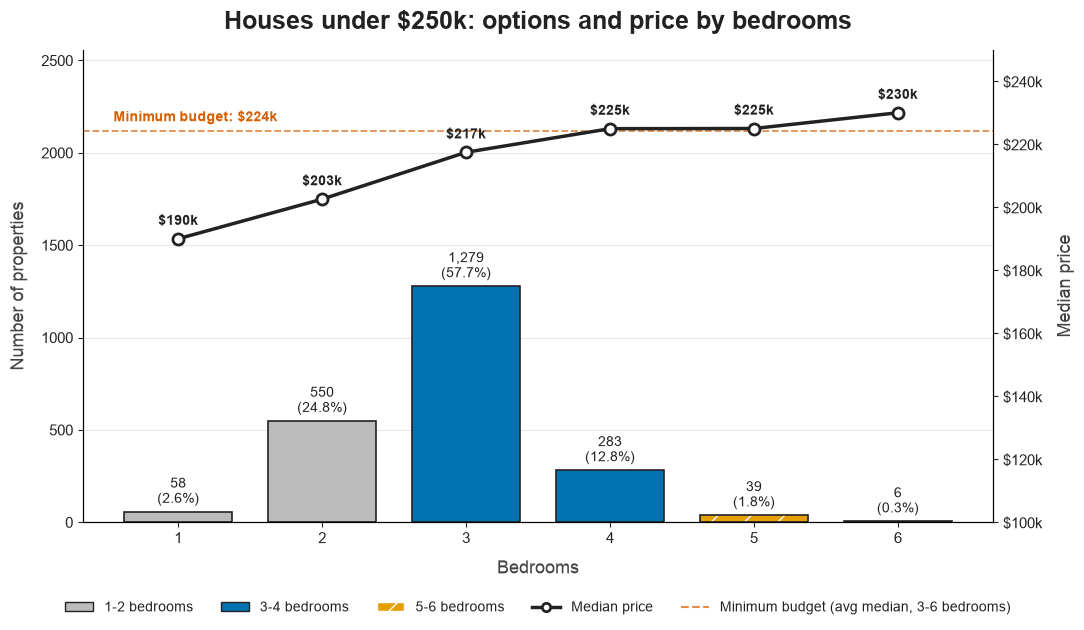

In [27]:
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import FuncFormatter
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
plt.rcParams["font.family"] = "Arial"
plt.rcParams["hatch.linewidth"] = 1.0

budget = df_unique[df_unique["price"] < 250_000].copy()

by_bed = budget.groupby("bedrooms").agg(n=("price", "size"),
                                        median_price=("price", "median"))
x = by_bed.index.astype(int).astype(str)
share = by_bed["n"] / by_bed["n"].sum() * 100

# categories: 1-2 too small (grey), 3-4 (blue), 5-6 (orange, pattern)
def style(b):
    if b <= 2:
        return "#BBBBBB", ""
    if b <= 4:
        return "#0072B2", ""
    return "#E69F00", "/"

fig, ax = plt.subplots(figsize=(11, 6.5))

bars = ax.bar(x, by_bed["n"], width=0.75, linewidth=0,
              color=[style(b)[0] for b in by_bed.index])
for bar, b in zip(bars, by_bed.index):
    hatch = style(b)[1]
    if hatch:
        bar.set_hatch(hatch)
        bar.set_edgecolor("white")
ax.bar(x, by_bed["n"], fill=False, edgecolor="#222222", linewidth=1.2, width=0.75)

for bar, n, pct in zip(bars, by_bed["n"], share):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + by_bed["n"].max() * 0.02,
            f"{n:,}\n({pct:.1f}%)", ha="center", va="bottom", fontsize=10)

# bars use only the lower half of the chart
ax.set_ylim(0, by_bed["n"].max() * 2)

# second axis: price line in the upper half
ax2 = ax.twinx()
ax2.set_ylim(100_000, 250_000)

# minimum budget = average of the median prices for 3-6 bedrooms
target = by_bed.loc[by_bed.index >= 3, "median_price"].mean()
ax2.axhline(target, color="#D55E00", linestyle="--", linewidth=1.3, alpha=0.7, zorder=1)
ax2.text(-0.45, target + 2_000, f"Minimum budget: ${target/1000:.0f}k",
         ha="left", va="bottom", fontsize=10, fontweight="bold", color="#D55E00")

ax2.plot(x, by_bed["median_price"], color="#222222", marker="o", markersize=8,
         markerfacecolor="white", markeredgewidth=2, linewidth=2.5, zorder=3)
for xi, med in zip(x, by_bed["median_price"]):
    ax2.annotate(f"${med/1000:.0f}k", (xi, med), textcoords="offset points",
                 xytext=(0, 10), ha="center", fontsize=10, fontweight="bold",
                 color="#222222")
ax2.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v/1000:.0f}k"))
ax2.set_ylabel("Median price", fontsize=13, color="#444444", labelpad=10)

ax.set_title("Houses under $250k: options and price by bedrooms",
             fontsize=18, fontweight="bold", color="#222222", pad=15)
ax.set_xlabel("Bedrooms", fontsize=13, color="#444444", labelpad=10)
ax.set_ylabel("Number of properties", fontsize=13, color="#444444", labelpad=10)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax2.spines["top"].set_visible(False)

# legend below the chart, one row
legend_items = [
    Patch(facecolor="#BBBBBB", edgecolor="#222222", label="1-2 bedrooms"),
    Patch(facecolor="#0072B2", edgecolor="#222222", label="3-4 bedrooms"),
    Patch(facecolor="#E69F00", edgecolor="white", hatch="/", label="5-6 bedrooms"),
    Line2D([0], [0], color="#222222", marker="o", markerfacecolor="white",
           markeredgewidth=2, linewidth=2.5, label="Median price"),
    Line2D([0], [0], color="#D55E00", linestyle="--", alpha=0.7,
           label="Minimum budget (avg median, 3-6 bedrooms)"),
]
ax.legend(handles=legend_items, loc="upper center", bbox_to_anchor=(0.5, -0.14),
          ncol=5, frameon=False, fontsize=10)

plt.tight_layout()
plt.show()

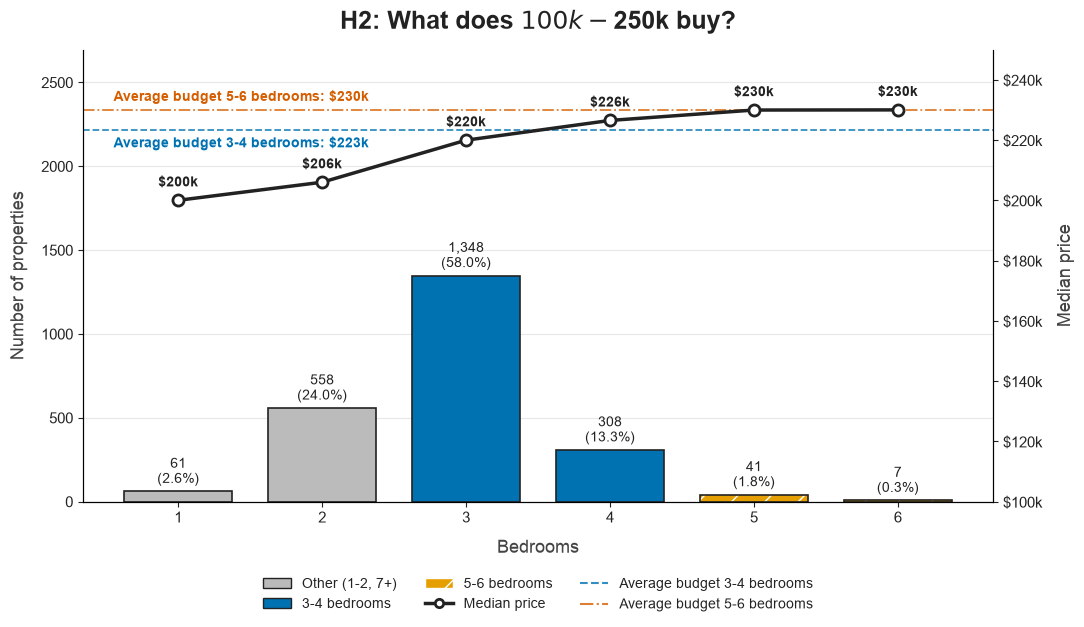

In [30]:
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import FuncFormatter
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
plt.rcParams["font.family"] = "Arial"
plt.rcParams["hatch.linewidth"] = 1.0

budget = df_unique[df_unique["price"].between(100_000, 250_000)].copy()
budget["bed_group"] = budget["bedrooms"].clip(upper=7).astype(int)   # 7 = "7+"

by_bed = budget.groupby("bed_group").agg(n=("price", "size"),
                                         median_price=("price", "median"))
x = [f"{b}+" if b == 7 else str(b) for b in by_bed.index]
share = by_bed["n"] / by_bed["n"].sum() * 100

# categories: 3-4 (blue), 5-6 (orange, pattern), others grey
def style(b):
    if 3 <= b <= 4:
        return "#0072B2", ""
    if 5 <= b <= 6:
        return "#E69F00", "/"
    return "#BBBBBB", ""

fig, ax = plt.subplots(figsize=(11, 6.5))

bars = ax.bar(x, by_bed["n"], width=0.75, linewidth=0,
              color=[style(b)[0] for b in by_bed.index])
for bar, b in zip(bars, by_bed.index):
    hatch = style(b)[1]
    if hatch:
        bar.set_hatch(hatch)
        bar.set_edgecolor("white")
ax.bar(x, by_bed["n"], fill=False, edgecolor="#222222", linewidth=1.2, width=0.75)

for bar, n, pct in zip(bars, by_bed["n"], share):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + by_bed["n"].max() * 0.02,
            f"{n:,}\n({pct:.1f}%)", ha="center", va="bottom", fontsize=10)

# bars use only the lower half of the chart
ax.set_ylim(0, by_bed["n"].max() * 2)

# second axis: price line in the upper half
ax2 = ax.twinx()
ax2.set_ylim(100_000, 250_000)

# average budget needed = average of the median prices per group
avg_34 = by_bed.loc[(by_bed.index >= 3) & (by_bed.index <= 4), "median_price"].mean()
avg_56 = by_bed.loc[(by_bed.index >= 5) & (by_bed.index <= 6), "median_price"].mean()

ax2.axhline(avg_34, color="#0072B2", linestyle="--", linewidth=1.3, alpha=0.8, zorder=1)
ax2.text(-0.45, avg_34 - 2_000, f"Average budget 3-4 bedrooms: ${avg_34/1000:.0f}k",
         ha="left", va="top", fontsize=10, fontweight="bold", color="#0072B2")

ax2.axhline(avg_56, color="#D55E00", linestyle="-.", linewidth=1.3, alpha=0.8, zorder=1)
ax2.text(-0.45, avg_56 + 2_000, f"Average budget 5-6 bedrooms: ${avg_56/1000:.0f}k",
         ha="left", va="bottom", fontsize=10, fontweight="bold", color="#D55E00")

ax2.plot(x, by_bed["median_price"], color="#222222", marker="o", markersize=8,
         markerfacecolor="white", markeredgewidth=2, linewidth=2.5, zorder=3)
for xi, med in zip(x, by_bed["median_price"]):
    ax2.annotate(f"${med/1000:.0f}k", (xi, med), textcoords="offset points",
                 xytext=(0, 10), ha="center", fontsize=10, fontweight="bold",
                 color="#222222")
ax2.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v/1000:.0f}k"))
ax2.set_ylabel("Median price", fontsize=13, color="#444444", labelpad=10)

ax.set_title("H2: What does $100k-$250k buy?",
             fontsize=18, fontweight="bold", color="#222222", pad=15)
ax.set_xlabel("Bedrooms", fontsize=13, color="#444444", labelpad=10)
ax.set_ylabel("Number of properties", fontsize=13, color="#444444", labelpad=10)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax2.spines["top"].set_visible(False)

# legend below the chart, two rows
legend_items = [
    Patch(facecolor="#BBBBBB", edgecolor="#222222", label="Other (1-2, 7+)"),
    Patch(facecolor="#0072B2", edgecolor="#222222", label="3-4 bedrooms"),
    Patch(facecolor="#E69F00", edgecolor="white", hatch="/", label="5-6 bedrooms"),
    Line2D([0], [0], color="#222222", marker="o", markerfacecolor="white",
           markeredgewidth=2, linewidth=2.5, label="Median price"),
    Line2D([0], [0], color="#0072B2", linestyle="--", alpha=0.8,
           label="Average budget 3-4 bedrooms"),
    Line2D([0], [0], color="#D55E00", linestyle="-.", alpha=0.8,
           label="Average budget 5-6 bedrooms"),
]
ax.legend(handles=legend_items, loc="upper center", bbox_to_anchor=(0.5, -0.14),
          ncol=3, frameon=False, fontsize=10)

plt.tight_layout()
plt.show()

In [31]:
budget["price_band"] = pd.cut(budget["price"], bins=[100_000, 200_000, 250_001],
                              labels=["$100k-200k", "$200k-250k"], right=False)

check = pd.crosstab(budget["bed_group"], budget["price_band"], margins=True, margins_name="Total")
check.index = [f"{b}+" if b == 7 else str(b) for b in check.index[:-1]] + ["Total"]
print(check)

price_band  $100k-200k  $200k-250k  Total
1                   30          31     61
2                  241         317    558
3                  370         978   1348
4                   57         251    308
5                   10          31     41
6                    1           6      7
Total              709        1614   2323


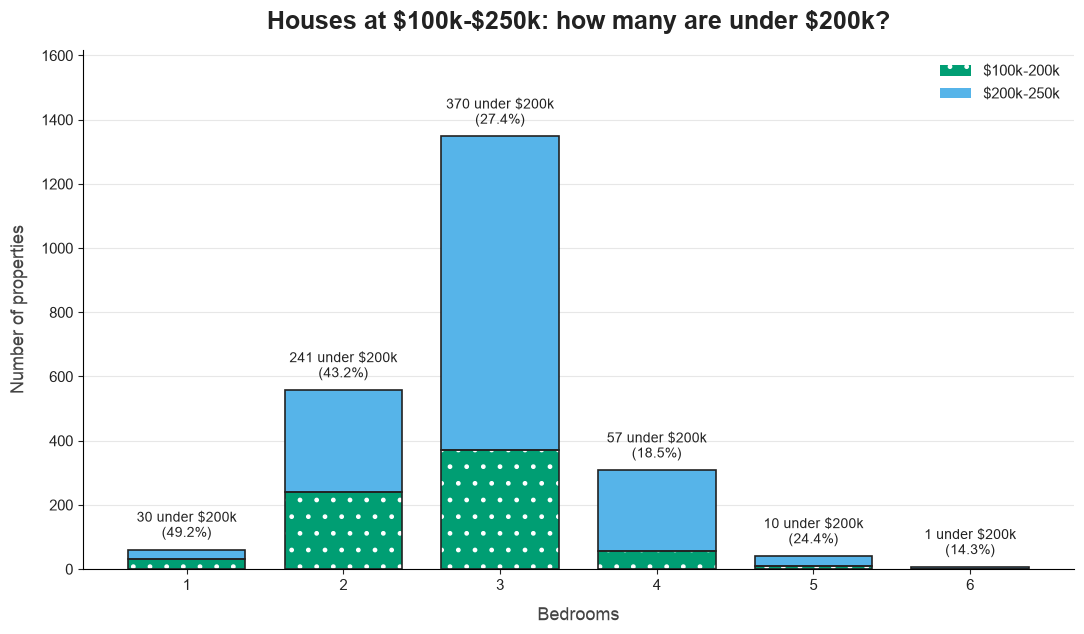

In [32]:
bands = (budget.groupby(["bed_group", "price_band"], observed=False).size()
         .unstack(fill_value=0))
x = [f"{b}+" if b == 7 else str(b) for b in bands.index]
total = bands.sum(axis=1)

fig, ax = plt.subplots(figsize=(11, 6.5))

# bottom: $100k-200k (green, white dots)
low = ax.bar(x, bands["$100k-200k"], color="#009E73", width=0.75, linewidth=0,
             label="$100k-200k")
for bar in low:
    bar.set_hatch(".")
    bar.set_edgecolor("white")

# top: $200k-250k (sky blue)
ax.bar(x, bands["$200k-250k"], bottom=bands["$100k-200k"], color="#56B4E9",
       width=0.75, linewidth=0, label="$200k-250k")

# dark outlines on both parts
ax.bar(x, bands["$100k-200k"], fill=False, edgecolor="#222222", linewidth=1.2, width=0.75)
ax.bar(x, bands["$200k-250k"], bottom=bands["$100k-200k"], fill=False,
       edgecolor="#222222", linewidth=1.2, width=0.75)

# label: houses under $200k and their share
for i, (n_low, t) in enumerate(zip(bands["$100k-200k"], total)):
    pct = n_low / t * 100 if t else 0
    ax.text(i, t + total.max() * 0.02, f"{n_low:,} under $200k\n({pct:.1f}%)",
            ha="center", va="bottom", fontsize=10)

ax.set_title("Houses at $100k-$250k: how many are under $200k?",
             fontsize=18, fontweight="bold", color="#222222", pad=15)
ax.set_xlabel("Bedrooms", fontsize=13, color="#444444", labelpad=10)
ax.set_ylabel("Number of properties", fontsize=13, color="#444444", labelpad=10)
ax.set_ylim(0, total.max() * 1.2)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
ax.legend(loc="upper right", frameon=False, fontsize=11)

plt.tight_layout()
plt.show()

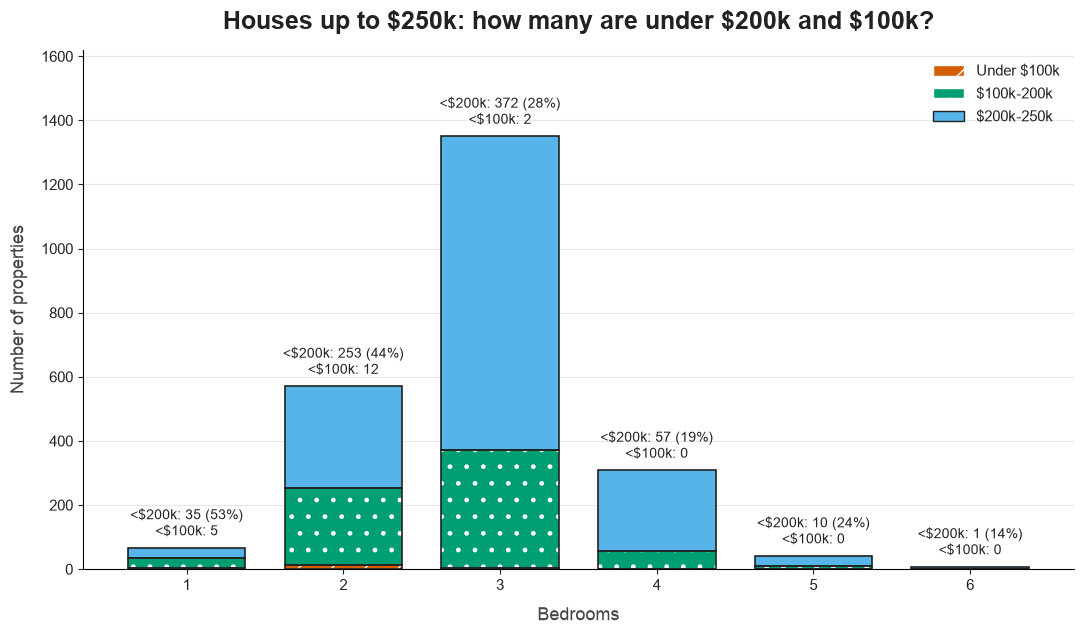

In [35]:
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.patches import Patch
plt.rcParams["font.family"] = "Arial"
plt.rcParams["hatch.linewidth"] = 1.0

# all houses up to $250k, including under $100k
upto250 = df_unique[df_unique["price"] <= 250_000].copy()
upto250["bed_group"] = upto250["bedrooms"].clip(upper=7).astype(int)   # 7 = "7+"
upto250["price_band"] = pd.cut(upto250["price"], bins=[0, 100_000, 200_000, 250_001],
                               labels=["Under $100k", "$100k-200k", "$200k-250k"], right=False)

bands = (upto250.groupby(["bed_group", "price_band"], observed=False).size()
         .unstack(fill_value=0))
x = [f"{b}+" if b == 7 else str(b) for b in bands.index]
total = bands.sum(axis=1)

b1 = bands["Under $100k"]
b2 = bands["$100k-200k"]
b3 = bands["$200k-250k"]

fig, ax = plt.subplots(figsize=(11, 6.5))

# bottom: under $100k (orange-red, white lines)
p1 = ax.bar(x, b1, color="#D55E00", width=0.75, linewidth=0)
for bar in p1:
    bar.set_hatch("/")
    bar.set_edgecolor("white")

# middle: $100k-200k (green, white dots)
p2 = ax.bar(x, b2, bottom=b1, color="#009E73", width=0.75, linewidth=0)
for bar in p2:
    bar.set_hatch(".")
    bar.set_edgecolor("white")

# top: $200k-250k (sky blue)
ax.bar(x, b3, bottom=b1 + b2, color="#56B4E9", width=0.75, linewidth=0)

# dark outlines on all three parts
ax.bar(x, b1, fill=False, edgecolor="#222222", linewidth=1.2, width=0.75)
ax.bar(x, b2, bottom=b1, fill=False, edgecolor="#222222", linewidth=1.2, width=0.75)
ax.bar(x, b3, bottom=b1 + b2, fill=False, edgecolor="#222222", linewidth=1.2, width=0.75)

# label: houses under $200k (with share) and under $100k
for i, (n1, n2, t) in enumerate(zip(b1, b2, total)):
    under200 = n1 + n2
    pct = under200 / t * 100 if t else 0
    ax.text(i, t + total.max() * 0.02,
            f"<$200k: {under200:,} ({pct:.0f}%)\n<$100k: {n1:,}",
            ha="center", va="bottom", fontsize=10)

ax.set_title("Houses up to $250k: how many are under $200k and $100k?",
             fontsize=18, fontweight="bold", color="#222222", pad=15)
ax.set_xlabel("Bedrooms", fontsize=13, color="#444444", labelpad=10)
ax.set_ylabel("Number of properties", fontsize=13, color="#444444", labelpad=10)
ax.set_ylim(0, total.max() * 1.2)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)

legend_items = [
    Patch(facecolor="#D55E00", edgecolor="white", hatch="/", label="Under $100k"),
    Patch(facecolor="#009E73", edgecolor="white", hatch=".", label="$100k-200k"),
    Patch(facecolor="#56B4E9", edgecolor="#222222", label="$200k-250k"),
]
ax.legend(handles=legend_items, loc="upper right", frameon=False, fontsize=11)

plt.tight_layout()
plt.show()

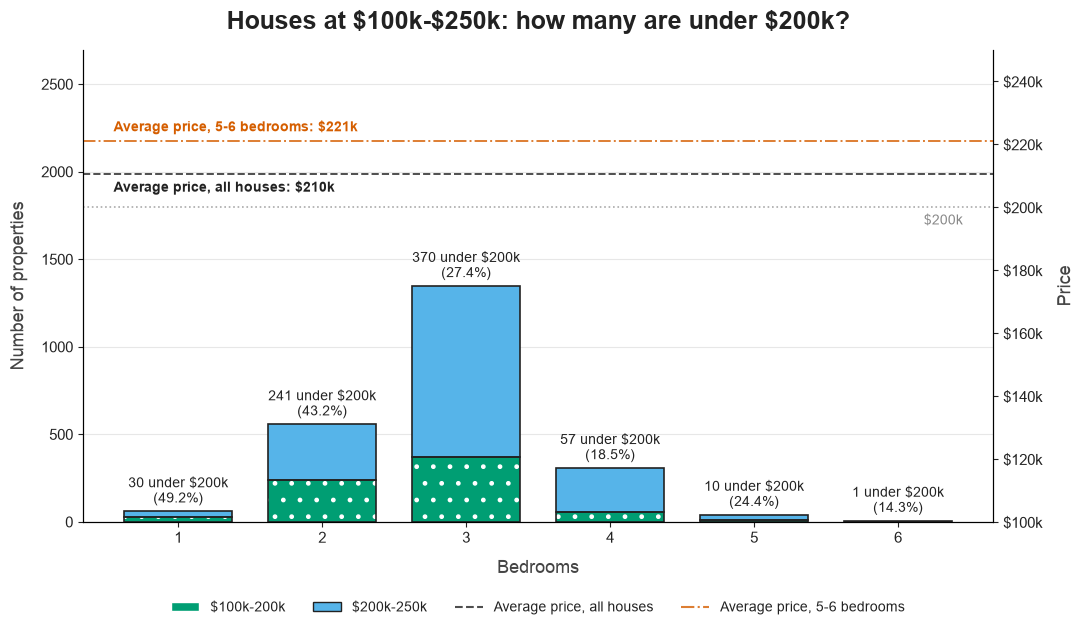

In [34]:
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import FuncFormatter
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
plt.rcParams["font.family"] = "Arial"
plt.rcParams["hatch.linewidth"] = 1.0

budget["price_band"] = pd.cut(budget["price"], bins=[100_000, 200_000, 250_001],
                              labels=["$100k-200k", "$200k-250k"], right=False)

bands = (budget.groupby(["bed_group", "price_band"], observed=False).size()
         .unstack(fill_value=0))
x = [f"{b}+" if b == 7 else str(b) for b in bands.index]
total = bands.sum(axis=1)

fig, ax = plt.subplots(figsize=(11, 6.5))

# bottom: $100k-200k (green, white dots)
low = ax.bar(x, bands["$100k-200k"], color="#009E73", width=0.75, linewidth=0)
for bar in low:
    bar.set_hatch(".")
    bar.set_edgecolor("white")

# top: $200k-250k (sky blue)
ax.bar(x, bands["$200k-250k"], bottom=bands["$100k-200k"], color="#56B4E9",
       width=0.75, linewidth=0)

# dark outlines on both parts
ax.bar(x, bands["$100k-200k"], fill=False, edgecolor="#222222", linewidth=1.2, width=0.75)
ax.bar(x, bands["$200k-250k"], bottom=bands["$100k-200k"], fill=False,
       edgecolor="#222222", linewidth=1.2, width=0.75)

# label: houses under $200k and their share
for i, (n_low, t) in enumerate(zip(bands["$100k-200k"], total)):
    pct = n_low / t * 100 if t else 0
    ax.text(i, t + total.max() * 0.02, f"{n_low:,} under $200k\n({pct:.1f}%)",
            ha="center", va="bottom", fontsize=10)

# bars use only the lower half, so the lines above stay clear
ax.set_ylim(0, total.max() * 2)

# second axis: average prices
ax2 = ax.twinx()
ax2.set_ylim(100_000, 250_000)

avg_all = budget["price"].mean()
avg_56 = budget.loc[budget["bedrooms"].between(5, 6), "price"].mean()

ax2.axhline(200_000, color="#AAAAAA", linestyle=":", linewidth=1.2, zorder=1)
ax2.text(len(x) - 0.55, 200_000 - 2_000, "$200k", ha="right", va="top",
         fontsize=10, color="#888888")

ax2.axhline(avg_all, color="#222222", linestyle="--", linewidth=1.4, alpha=0.8, zorder=2)
ax2.text(-0.45, avg_all - 2_000, f"Average price, all houses: ${avg_all/1000:.0f}k",
         ha="left", va="top", fontsize=10, fontweight="bold", color="#222222")

ax2.axhline(avg_56, color="#D55E00", linestyle="-.", linewidth=1.4, alpha=0.8, zorder=2)
ax2.text(-0.45, avg_56 + 2_000, f"Average price, 5-6 bedrooms: ${avg_56/1000:.0f}k",
         ha="left", va="bottom", fontsize=10, fontweight="bold", color="#D55E00")

ax2.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v/1000:.0f}k"))
ax2.set_ylabel("Price", fontsize=13, color="#444444", labelpad=10)

ax.set_title("Houses at $100k-$250k: how many are under $200k?",
             fontsize=18, fontweight="bold", color="#222222", pad=15)
ax.set_xlabel("Bedrooms", fontsize=13, color="#444444", labelpad=10)
ax.set_ylabel("Number of properties", fontsize=13, color="#444444", labelpad=10)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax2.spines["top"].set_visible(False)

# legend below the chart
legend_items = [
    Patch(facecolor="#009E73", edgecolor="white", hatch=".", label="$100k-200k"),
    Patch(facecolor="#56B4E9", edgecolor="#222222", label="$200k-250k"),
    Line2D([0], [0], color="#222222", linestyle="--", alpha=0.8, label="Average price, all houses"),
    Line2D([0], [0], color="#D55E00", linestyle="-.", alpha=0.8, label="Average price, 5-6 bedrooms"),
]
ax.legend(handles=legend_items, loc="upper center", bbox_to_anchor=(0.5, -0.14),
          ncol=4, frameon=False, fontsize=10)

plt.tight_layout()
plt.show()

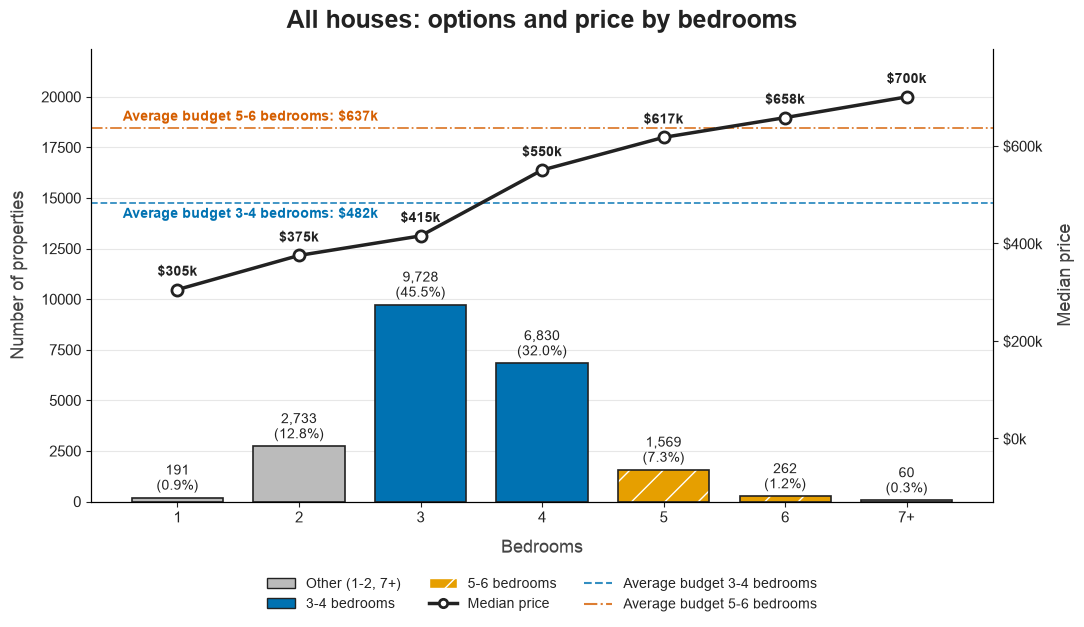

In [29]:
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import FuncFormatter
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
plt.rcParams["font.family"] = "Arial"
plt.rcParams["hatch.linewidth"] = 1.0

df_all = df_unique.copy()
df_all["bed_group"] = df_all["bedrooms"].clip(upper=7).astype(int)   # 7 = "7+"

by_bed = df_all.groupby("bed_group").agg(n=("price", "size"),
                                         median_price=("price", "median"))
x = [f"{b}+" if b == 7 else str(b) for b in by_bed.index]
share = by_bed["n"] / by_bed["n"].sum() * 100

# categories: 3-4 (blue), 5-6 (orange, pattern), others grey
def style(b):
    if 3 <= b <= 4:
        return "#0072B2", ""
    if 5 <= b <= 6:
        return "#E69F00", "/"
    return "#BBBBBB", ""

fig, ax = plt.subplots(figsize=(11, 6.5))

bars = ax.bar(x, by_bed["n"], width=0.75, linewidth=0,
              color=[style(b)[0] for b in by_bed.index])
for bar, b in zip(bars, by_bed.index):
    hatch = style(b)[1]
    if hatch:
        bar.set_hatch(hatch)
        bar.set_edgecolor("white")
ax.bar(x, by_bed["n"], fill=False, edgecolor="#222222", linewidth=1.2, width=0.75)

for bar, n, pct in zip(bars, by_bed["n"], share):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + by_bed["n"].max() * 0.02,
            f"{n:,}\n({pct:.1f}%)", ha="center", va="bottom", fontsize=10)

# bars use only the lower part of the chart
ax.set_ylim(0, by_bed["n"].max() * 2.3)

# second axis: price line in the upper part (limits adapt to the data)
ax2 = ax.twinx()
mn, mx = by_bed["median_price"].min(), by_bed["median_price"].max()
span = mx - mn
ax2.set_ylim(mn - span * 1.1, mx + span * 0.25)

# average budget needed = average of the median prices per group
avg_34 = by_bed.loc[(by_bed.index >= 3) & (by_bed.index <= 4), "median_price"].mean()
avg_56 = by_bed.loc[(by_bed.index >= 5) & (by_bed.index <= 6), "median_price"].mean()

ax2.axhline(avg_34, color="#0072B2", linestyle="--", linewidth=1.3, alpha=0.8, zorder=1)
ax2.text(-0.45, avg_34 - span * 0.02, f"Average budget 3-4 bedrooms: ${avg_34/1000:.0f}k",
         ha="left", va="top", fontsize=10, fontweight="bold", color="#0072B2")

ax2.axhline(avg_56, color="#D55E00", linestyle="-.", linewidth=1.3, alpha=0.8, zorder=1)
ax2.text(-0.45, avg_56 + span * 0.02, f"Average budget 5-6 bedrooms: ${avg_56/1000:.0f}k",
         ha="left", va="bottom", fontsize=10, fontweight="bold", color="#D55E00")

ax2.plot(x, by_bed["median_price"], color="#222222", marker="o", markersize=8,
         markerfacecolor="white", markeredgewidth=2, linewidth=2.5, zorder=3)
for xi, med in zip(x, by_bed["median_price"]):
    ax2.annotate(f"${med/1000:.0f}k", (xi, med), textcoords="offset points",
                 xytext=(0, 10), ha="center", fontsize=10, fontweight="bold",
                 color="#222222")
# hide negative tick labels on the price axis
ax2.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v/1000:.0f}k" if v >= 0 else ""))
ax2.set_ylabel("Median price", fontsize=13, color="#444444", labelpad=10)

ax.set_title("All houses: options and price by bedrooms",
             fontsize=18, fontweight="bold", color="#222222", pad=15)
ax.set_xlabel("Bedrooms", fontsize=13, color="#444444", labelpad=10)
ax.set_ylabel("Number of properties", fontsize=13, color="#444444", labelpad=10)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax2.spines["top"].set_visible(False)

# legend below the chart, two rows
legend_items = [
    Patch(facecolor="#BBBBBB", edgecolor="#222222", label="Other (1-2, 7+)"),
    Patch(facecolor="#0072B2", edgecolor="#222222", label="3-4 bedrooms"),
    Patch(facecolor="#E69F00", edgecolor="white", hatch="/", label="5-6 bedrooms"),
    Line2D([0], [0], color="#222222", marker="o", markerfacecolor="white",
           markeredgewidth=2, linewidth=2.5, label="Median price"),
    Line2D([0], [0], color="#0072B2", linestyle="--", alpha=0.8,
           label="Average budget 3-4 bedrooms"),
    Line2D([0], [0], color="#D55E00", linestyle="-.", alpha=0.8,
           label="Average budget 5-6 bedrooms"),
]
ax.legend(handles=legend_items, loc="upper center", bbox_to_anchor=(0.5, -0.14),
          ncol=3, frameon=False, fontsize=10)

plt.tight_layout()
plt.show()